In [1]:
# neural network training with backpropagation 
# 1 hidden layer with 4 neurons, 1 output layer with 1 neuron (binary classification)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

np.random.seed(1)

In [2]:
# generate synthetic dataset
m = 200
n_x = 2

m_half = m // 2
X0 = np.random.randn(m_half, n_x) + np.array([-2.0, -2.0])
X1 = np.random.randn(m - m_half, n_x) + np.array([2.0, 2.0])

X = np.vstack([X0, X1]).T
Y = np.hstack([np.zeros(m_half), np.ones(m - m_half)]).reshape(1, m)

perm = np.random.permutation(m)
X, Y = X[:, perm], Y[:, perm]

X.shape, Y.shape

((2, 200), (1, 200))

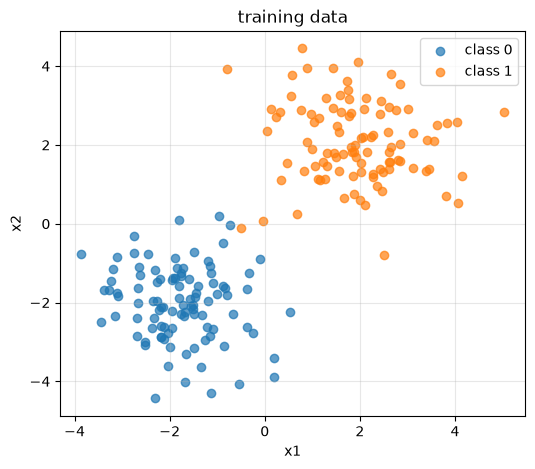

In [3]:
# plot generated data
y = Y.ravel() # convert to 1D array for plotting

plt.figure(figsize=(6, 5))
plt.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", alpha=0.7, label="class 0")
plt.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", alpha=0.7, label="class 1")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("training data")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [5]:
# this function plots the decision boundary of a classifier 
def plot_boundary(predict, X, Y, title):
    yv = Y.ravel()
    x_min, x_max = X[0].min()-1, X[0].max()+1
    y_min, y_max = X[1].min()-1, X[1].max()+1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    grid = np.c_[xx.ravel(), yy.ravel()].T
    Z = predict(grid).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.coolwarm)
    plt.scatter(X[0, yv == 0], X[1, yv == 0], c="tab:blue", alpha=0.7, label="class 0")
    plt.scatter(X[0, yv == 1], X[1, yv == 1], c="tab:orange", alpha=0.7, label="class 1")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

In [6]:
def train_logreg(X, Y, iters=2000, lr=0.5):
    n, m = X.shape
    w = np.zeros((1, n))
    b = 0.0
    for i in range(iters):
        A = sigmoid(w @ X + b)
        dZ = A - Y
        w -= lr * (dZ @ X.T) / m
        b -= lr * np.sum(dZ) / m
    return w, b

w, b = train_logreg(X, Y)
pred = sigmoid(w @ X + b) > 0.5
print('logreg accuracy:', np.mean(pred == Y))

logreg accuracy: 0.995


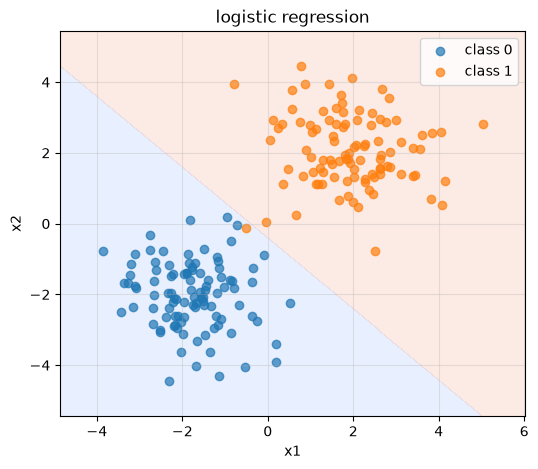

In [7]:
plot_boundary(lambda G: sigmoid(w @ G + b) > 0.5, X, Y, 'logistic regression')

In [8]:
def init_params(n_x, n_h, n_y):
    W1 = np.random.randn(n_h, n_x) * 0.01 # dont use zeros for weights, otherwise the neurons will be symmetric and learn the same features
    b1 = np.zeros((n_h, 1)) # biases can be initialized to zeros
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))
    return [W1, b1, W2, b2]

In [9]:
def forward(X, params):
    W1, b1, W2, b2 = params 
    Z1 = W1 @ X + b1 # z1 = W1 * X + b1
    A1 = np.tanh(Z1) # activation function for hidden layer (hyperbolic tangent)
    Z2 = W2 @ A1 + b2 # z2 = W2 * A1 + b2
    A2 = sigmoid(Z2) # sigmoid activation for output layer (binary classification)
    return Z1, A1, Z2, A2

In [10]:
def compute_cost(A2, Y):
    m = Y.shape[1] # number of training examples
    A2 = np.clip(A2, 1e-8, 1-1e-8) # clip A2 to avoid log(0) which is undefined
    return -np.sum(Y*np.log(A2) + (1-Y)*np.log(1-A2)) / m # cost function is the average of the negative log-likelihood

In [11]:
def backward(X, Y, params, cache):
    W1, b1, W2, b2 = params
    Z1, A1, Z2, A2 = cache 
    m = X.shape[1] # number of training examples
    # compute gradients using backpropagation
    dZ2 = A2 - Y 
    dW2 = (dZ2 @ A1.T) / m
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m
    dZ1 = (W2.T @ dZ2) * (1 - A1**2)
    dW1 = (dZ1 @ X.T) / m
    db1 = np.sum(dZ1, axis=1, keepdims=True) / m
    return [dW1, db1, dW2, db2]

In [12]:
def train_nn(X, Y, n_h=4, iters=10000, lr=0.3):
    params = init_params(X.shape[0], n_h, Y.shape[0]) # initialize parameters with input size, hidden layer size, and output size
    costs, params_hist = [], [] 
    for i in range(iters):
        cache = forward(X, params) # forward pass
        grads = backward(X, Y, params, cache) # backward pass
        for k in range(4):
            params[k] -= lr * grads[k] # update parameters using gradient descent
        costs.append(compute_cost(cache[3], Y)) # compute cost and store it
        params_hist.append([p.copy() for p in params]) # store a copy of the parameters for history
    return params, costs, params_hist

params, costs, hist = train_nn(X, Y)

nn accuracy: 1.0


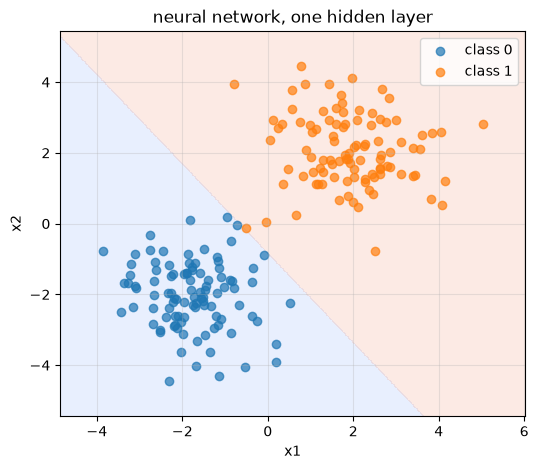

In [13]:
def nn_predict(G, params):
    return forward(G, params)[3] > 0.5 # return predictions based on the output of the forward pass

pred = nn_predict(X, params) # make predictions from trained neural network
print('nn accuracy:', np.mean(pred == Y))
plot_boundary(lambda G: nn_predict(G, params), X, Y, 'neural network, one hidden layer')

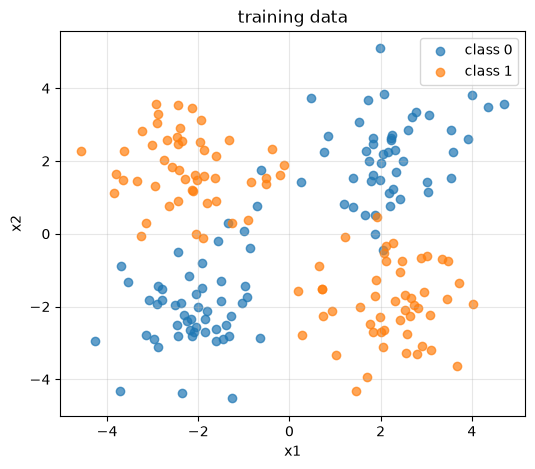

In [14]:
# generate non-separable XOR dataset, class 0 clouds centered at (-2, -2) and (2, 2), class 1 clouds centered at (-2, 2) and (2, -2)
def load_xor(m=200):
    q = m // 4
    centers = [([-2,-2], 0), ([2,2], 0), ([-2,2], 1), ([2,-2], 1)]
    Xs, Ys = [], []
    for c, label in centers:
        Xs.append(np.random.randn(q, 2) + np.array(c))
        Ys.append(np.full(q, label))
    Xx = np.vstack(Xs).T
    Yy = np.hstack(Ys).reshape(1, -1)
    p = np.random.permutation(Xx.shape[1])
    return Xx[:, p], Yy[:, p]

# plot XOR dataset
Xx, Yy = load_xor()
yy = Yy.ravel()
plt.figure(figsize=(6, 5))
plt.scatter(Xx[0, yy == 0], Xx[1, yy == 0], c="tab:blue", alpha=0.7, label="class 0")
plt.scatter(Xx[0, yy == 1], Xx[1, yy == 1], c="tab:orange", alpha=0.7, label="class 1")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("training data")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

logreg accuracy: 0.485


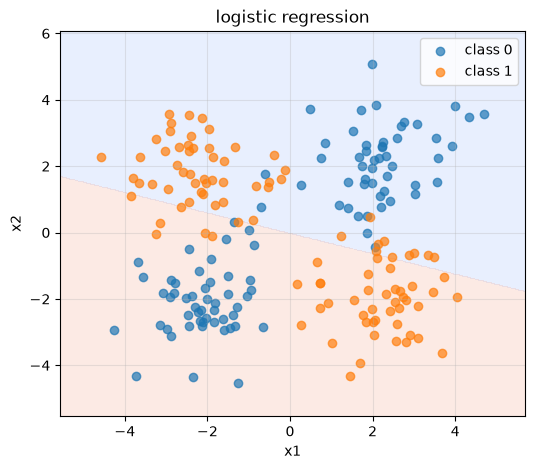

In [15]:
# train logistic regression on XOR dataset
w2, b2_ = train_logreg(Xx, Yy)
print('logreg accuracy:', np.mean((sigmoid(w2 @ Xx + b2_) > 0.5) == Yy))
plot_boundary(lambda G: sigmoid(w2 @ G + b2_) > 0.5, Xx, Yy, 'logistic regression')

nn accuracy: 0.965


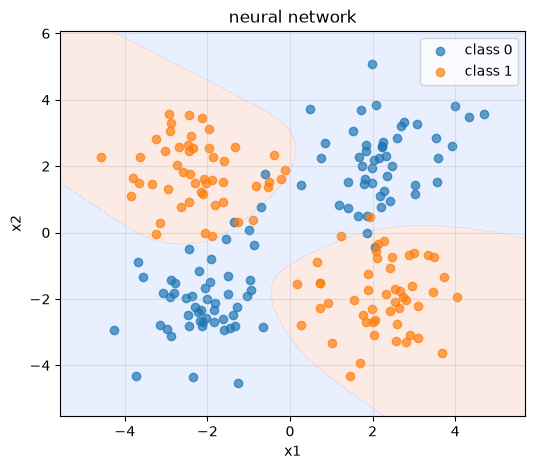

In [16]:
# train neural network on XOR dataset
params_xor, cost_xor, _ = train_nn(Xx, Yy, n_h=4, iters=10000, lr=0.3)
print('nn accuracy:', np.mean(nn_predict(Xx, params_xor) == Yy))
plot_boundary(lambda G: nn_predict(G, params_xor), Xx, Yy, 'neural network')

NameError: name 'grid' is not defined

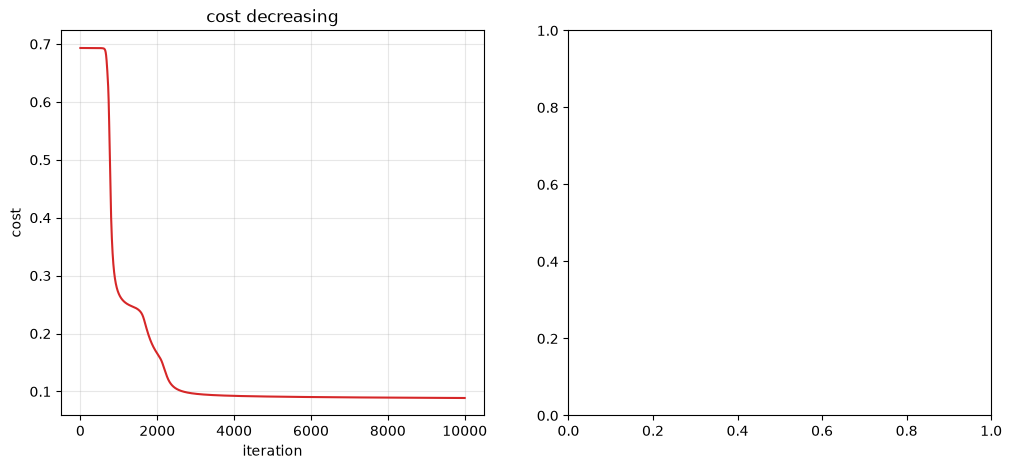

In [17]:
# train neural network on XOR dataset with 4 hidden neurons and plot cost and decision boundary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(cost_xor, color="tab:red")
ax1.set_xlabel("iteration"); ax1.set_ylabel("cost"); ax1.set_title("cost decreasing")
ax1.grid(alpha=0.3)

probs_grid = forward(grid, params_xor)[3].reshape(xx1.shape)
ax2.contourf(xx1, xx2, probs_grid, levels=20, cmap="coolwarm", alpha=0.6)
ax2.contour(xx1, xx2, probs_grid, levels=[0.5], colors="k", linestyles="--")
ax2.scatter(Xa[0, ya == 0], Xa[1, ya == 0], c="tab:blue", alpha=0.7, label="class 0")
ax2.scatter(Xa[0, ya == 1], Xa[1, ya == 1], c="tab:orange", alpha=0.7, label="class 1")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_title("final result")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

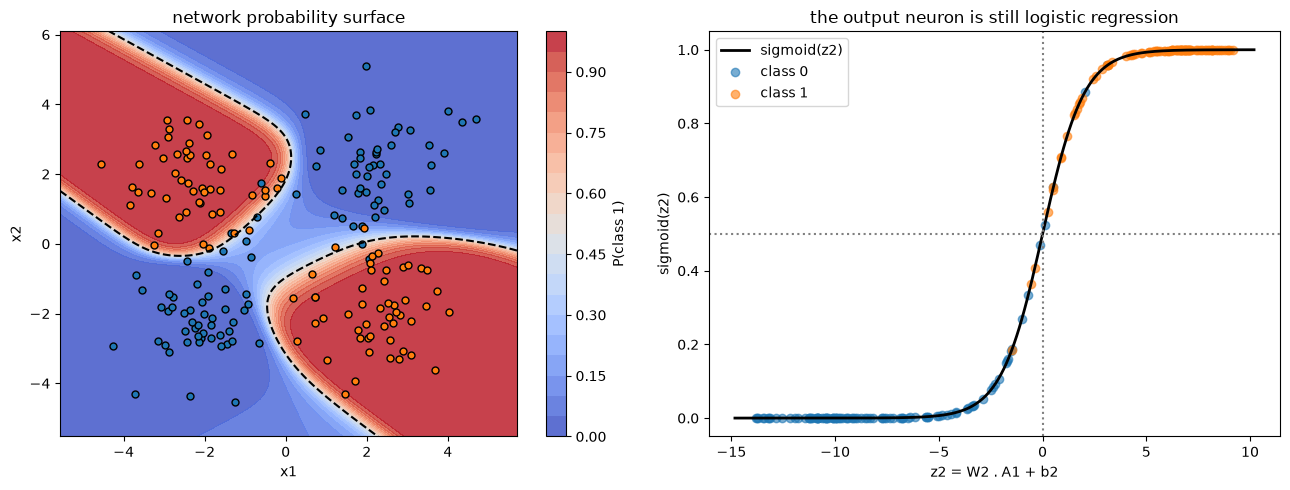

In [ ]:
probs_grid = forward(grid, params_xor)[3].reshape(xx1.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cf = ax1.contourf(xx1, xx2, probs_grid, levels=20, cmap="coolwarm", alpha=0.85)
ax1.contour(xx1, xx2, probs_grid, levels=[0.5], colors="k", linestyles="--")
ax1.scatter(Xa[0, ya == 0], Xa[1, ya == 0], c="tab:blue", edgecolor="k", s=25)
ax1.scatter(Xa[0, ya == 1], Xa[1, ya == 1], c="tab:orange", edgecolor="k", s=25)
fig.colorbar(cf, ax=ax1, label="P(class 1)")
ax1.set_xlabel("x1"); ax1.set_ylabel("x2")
ax1.set_title("network probability surface")

Z1, A1, Z2, A2 = forward(Xa, params_xor)
z2 = Z2.ravel()
z_line = np.linspace(z2.min() - 1, z2.max() + 1, 200)
ax2.plot(z_line, sigmoid(z_line), "k-", lw=2, label="sigmoid(z2)")
ax2.scatter(z2[ya == 0], sigmoid(z2[ya == 0]), c="tab:blue", alpha=0.6, label="class 0")
ax2.scatter(z2[ya == 1], sigmoid(z2[ya == 1]), c="tab:orange", alpha=0.6, label="class 1")
ax2.axhline(0.5, color="gray", ls=":"); ax2.axvline(0, color="gray", ls=":")
ax2.set_xlabel("z2 = W2 . A1 + b2"); ax2.set_ylabel("sigmoid(z2)")
ax2.set_title("the output neuron is still logistic regression")
ax2.legend()

plt.tight_layout(); plt.show()

In [ ]:
def nn_predict_proba(X_new, params):
    A2 = forward(X_new, params)[3]
    return A2.ravel(), (A2.ravel() >= 0.5).astype(int)

X_new = np.array([[-3.0, 3.0, 0.0, -1.0, 2.0],
                  [-2.0, 2.5, 0.0,  1.5, -1.0]])

probs, labels = nn_predict_proba(X_new, params_xor)

for i in range(X_new.shape[1]):
    p1, p2 = X_new[0, i], X_new[1, i]
    print(f"point ({p1:5.1f}, {p2:5.1f})  ->  P(class 1) = {probs[i]:.3f}  ->  class {labels[i]}")

point ( -3.0,  -2.0)  ->  P(class 1) = 0.000  ->  class 0
point (  3.0,   2.5)  ->  P(class 1) = 0.000  ->  class 0
point (  0.0,   0.0)  ->  P(class 1) = 0.191  ->  class 0
point ( -1.0,   1.5)  ->  P(class 1) = 0.982  ->  class 1
point (  2.0,  -1.0)  ->  P(class 1) = 0.983  ->  class 1


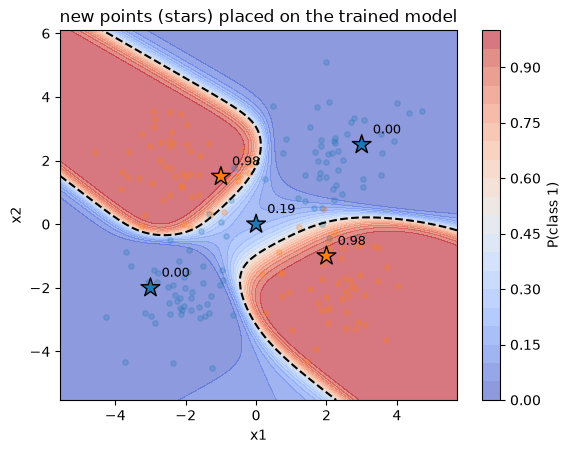

In [ ]:
probs_grid = forward(grid, params_xor)[3].reshape(xx1.shape)

cf = plt.contourf(xx1, xx2, probs_grid, levels=20, cmap="coolwarm", alpha=0.6)
plt.contour(xx1, xx2, probs_grid, levels=[0.5], colors="k", linestyles="--")
plt.scatter(Xa[0, ya == 0], Xa[1, ya == 0], c="tab:blue", alpha=0.25, s=15)
plt.scatter(Xa[0, ya == 1], Xa[1, ya == 1], c="tab:orange", alpha=0.25, s=15)

new_colors = ["tab:orange" if l == 1 else "tab:blue" for l in labels]
plt.scatter(X_new[0], X_new[1], c=new_colors, edgecolor="k", s=200, marker="*", zorder=5)
for i in range(X_new.shape[1]):
    plt.annotate(f"{probs[i]:.2f}", (X_new[0, i], X_new[1, i]),
                 textcoords="offset points", xytext=(8, 8), fontsize=9)

plt.colorbar(cf, label="P(class 1)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("new points (stars) placed on the trained model")
plt.show()